# NB-07 — Modelos ocultos de Markov (Cap. 2, §2.3)

> **Demonstração didática.** Base Washington (GW20, CIIR/UMass, uso não comercial, não redistribuir): 20 páginas, treino em CPU, vocabulário fechado. Os números **não** são comparáveis com a literatura nem com o BRESSAY; servem para mostrar o mecanismo de cada família do Cap. 2. Dados em `notebooks/dados/washington/` (fora do git; ver `lib/gw_demo.py`).

Um HMM gaussiano **esquerda-direita** por palavra; a imagem vira uma sequência de colunas (janela deslizante) e a classe é a de maior verossimilhança (`score`).

In [1]:
# Parâmetros
from pathlib import Path
SAIDA = Path('saidas/NB-07')
SEED = 0


In [2]:
import sys
sys.path.insert(0, '.')
import numpy as np, matplotlib.pyplot as plt
from lib import gw_demo as gw, gw_modelos as m
SAIDA.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
tr, va, te = m.carregar(gw.TREINO), m.carregar(gw.VALID), m.carregar(gw.TESTE)
print(f'palavras: treino {len(tr[0])} (páginas 0-13) | validação {len(va[0])} | teste {len(te[0])} (páginas 17-19)')

palavras: treino 3439 (páginas 0-13) | validação 684 | teste 707 (páginas 17-19)


In [3]:
VOC = m.top_palavras(tr[1], k=20, minimo=8)       # vocabulário fechado: as 20 palavras mais frequentes
Xtr, ytr = m.filtrar(*tr, VOC); Xva, yva = m.filtrar(*va, VOC); Xte, yte = m.filtrar(*te, VOC)
ytr, yva, yte = map(np.array, (ytr, yva, yte))
print(VOC); print('amostras:', len(Xtr), len(Xva), len(Xte))

['the', 'to', 'and', 'of', 'you', 'are', 'be', 'for', 'that', 'i', 'as', 'with', 'in', 'at', 'is', 'your', 'a', 'they', 'will', 'which']
amostras: 1176 213 252


## 1. Observações: uma coluna de pixels por passo de tempo

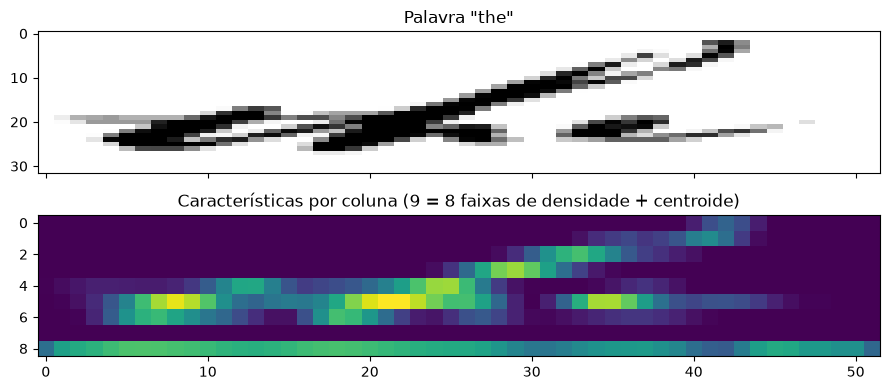

In [4]:
i = int(np.where(ytr == 0)[0][0])
f = m.feixe_colunas(Xtr[i])
fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
ax[0].imshow(Xtr[i], cmap='gray_r', aspect='auto'); ax[0].set_title(f'Palavra "{VOC[ytr[i]]}"')
ax[1].imshow(f.T, aspect='auto', cmap='viridis'); ax[1].set_title('Características por coluna (9 = 8 faixas de densidade + centroide)')
plt.tight_layout(); plt.savefig(SAIDA/'observacoes.png', dpi=130); plt.show()

## 2. Treino (Baum-Welch) e decodificação

In [5]:
import warnings; warnings.filterwarnings('ignore')
import logging; logging.getLogger('hmmlearn').setLevel(logging.ERROR)
H = m.treinar_hmms(Xtr, ytr, len(VOC), estados=6, seed=SEED)
pred = m.prever_hmms(H, Xte)
print(f'Acurácia HMM ({len(H)} modelos, 6 estados): {(pred == yte).mean():.3f}  (acaso ≈ {1/len(VOC):.3f})')

Acurácia HMM (20 modelos, 6 estados): 0.433  (acaso ≈ 0.050)


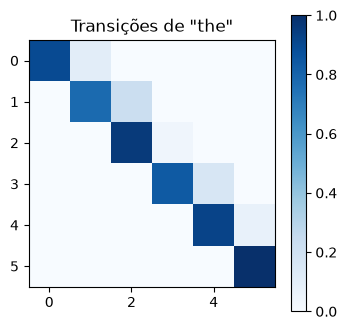

In [6]:
# Matriz de transição de um modelo: estrutura esquerda-direita
fig, ax = plt.subplots(figsize=(3.6, 3.4)); k = VOC.index('the') if 'the' in VOC else 0
im = ax.imshow(H[k].transmat_, cmap='Blues'); ax.set_title(f'Transições de "{VOC[k]}"'); plt.colorbar(im)
plt.tight_layout(); plt.savefig(SAIDA/'transicoes.png', dpi=130); plt.show()

**Leitura:** cada estado "cobre" um trecho da palavra e só se avança para a direita. Com poucas amostras por classe e características simples o desempenho é modesto, e o HMM exige um modelo por palavra (ou por caractere, com léxico). Isso ilustra por que a era HMM dependia de engenharia de características e modelos de linguagem.